# Lab 05 · Simple Linear Regression
**CS-3105 Machine Learning Lab** · Lab Instructor: Engr. Muhammad Awais

**CLO 7** (C-3 Apply, PLO 4 Investigation): *Apply machine learning algorithms and assess their performance using appropriate evaluation metrics.*

**Goal:** build a complete price predictor for one car on real data: prepare the data, split it, train a simple linear regression with the least squares method, test it on unseen ads, and use it.

**Data:** `pakistan_used_cars_clean.csv`, the cleaned OLX Pakistan used-car ads from Lab 03 (Open Data Pakistan, 2021). Use the copy given with this lab so everyone has the same file.

**Rules:** label every output, e.g. `print("T5a:", ...)` · use `random_state=42` for the split · written answers go in Markdown cells · Runtime → Restart and run all before you submit · push to `ML-Lab-<RollNo>/Lab05/Lab05.ipynb` by the deadline announced in class (11:59 PM PKT).

Name: Syeda Ayesha Batool  Roll No: 2024-SE-19

### Setup (run first, do not edit)
Put `pakistan_used_cars_clean.csv` next to this notebook (Colab: folder icon → Upload).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
pd.set_option('display.width', 140)

## Task 1 · Load and explore the real data
- **(a)** Load `pakistan_used_cars_clean.csv` and print its shape.
- **(b)** Keep only **Corolla GLI**, **Cash** ads, `Year` 2005–2018 and `Price_lakh` between 5 and 40. Save it as `gli` and print the shape.
- **(c)** Summary statistics (`describe()`) of `Age` and `Price_lakh`.
- **(d)** The correlation between `Age` and `Price_lakh`.
- **(e)** A scatter plot of `Price_lakh` against `Age`, with a title and axis labels.

**Write (Markdown):** is a straight line a sensible model for this data? Use (d) and (e).

T1(a) Dataset shape: (20484, 11)
T1(b) Filtered dataset shape: (796, 11)
T1(c) Summary statistics:
              Age  Price_lakh
count  796.000000  796.000000
mean     6.445980   16.586237
std      3.107847    3.984407
min      2.000000    6.543210
25%      4.000000   13.500000
50%      6.000000   16.500000
75%      9.000000   19.500000
max     15.000000   30.000000
T1(d) Correlation: -0.8956521001869919


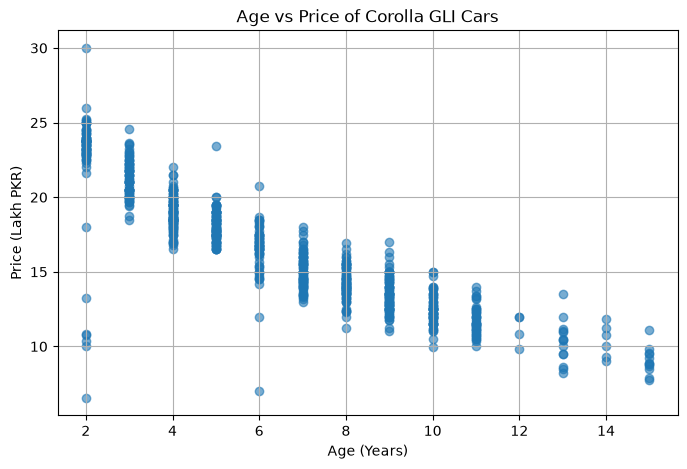

In [2]:

# Task 1(a): Load the dataset and print its shape

df = pd.read_csv("pakistan_used_cars_clean.csv")

print("T1(a) Dataset shape:", df.shape)


# Task 1(b): Filter the required Corolla GLI cars

gli = df[
    (df["Model"] == "Corolla GLI") &
    (df["Transaction Type"] == "Cash") &
    (df["Year"].between(2005, 2018)) &
    (df["Price_lakh"].between(5, 40))
]

print("T1(b) Filtered dataset shape:", gli.shape)


# Task 1(c): Summary statistics of Age and Price_lakh

print("T1(c) Summary statistics:")
print(gli[["Age", "Price_lakh"]].describe())


# Task 1(d): Correlation between Age and Price_lakh

correlation = gli["Age"].corr(gli["Price_lakh"])

print("T1(d) Correlation:", correlation)


# Task 1(e): Scatter plot

plt.figure(figsize=(8, 5))

plt.scatter(gli["Age"], gli["Price_lakh"], alpha=0.6)

plt.title("Age vs Price of Corolla GLI Cars")
plt.xlabel("Age (Years)")
plt.ylabel("Price (Lakh PKR)")
plt.grid(True)

plt.show()




A straight-line model is a sensible choice for this data. The correlation between Age and Price_lakh is approximately -0.896, which shows a strong negative relationship. The scatter plot also shows that the price of cars generally decreases as their age increases. Although the points do not form a perfectly straight line, a linear regression model can provide a useful estimate of car prices.


## Task 2 · Features, target and the train/test split
- **(a)** `X` = the `Age` column as a **2-D** table, `y` = `Price_lakh`. Print both shapes.
- **(b)** Split 80 % train / 20 % test with `train_test_split(..., test_size=0.2, random_state=42)`. Print the four shapes.

In [3]:

# Task 2(a): Select the feature (X) and target (y)

X = gli[["Age"]]
y = gli["Price_lakh"]

print("T2(a) Feature shape (X):", X.shape)
print("T2(a) Target shape (y):", y.shape)


# Task 2(b): Split the data into training and testing sets

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("T2(b) Training features shape:", X_train.shape)
print("T2(b) Testing features shape:", X_test.shape)
print("T2(b) Training target shape:", y_train.shape)
print("T2(b) Testing target shape:", y_test.shape)



T2(a) Feature shape (X): (796, 1)
T2(a) Target shape (y): (796,)
T2(b) Training features shape: (636, 1)
T2(b) Testing features shape: (160, 1)
T2(b) Training target shape: (636,)
T2(b) Testing target shape: (160,)


## Task 3 · Least squares with NumPy (training data only)
Use only `X_train` and `y_train`, and NumPy (no scikit-learn):
- **(a)** The means x̄ and ȳ.
- **(b)** The slope b₁ = Σ(x − x̄)(y − ȳ) / Σ(x − x̄)² and the intercept b₀ = ȳ − b₁x̄.
- **(c)** **Write (Markdown):** what b₁ and b₀ mean for a Corolla GLI, with units.

In [4]:

# Task 3(a): Calculate the means using training data only

x = X_train["Age"].to_numpy()
y = y_train.to_numpy()

x_bar = np.mean(x)
y_bar = np.mean(y)

print("T3(a) Mean of Age:", x_bar)
print("T3(a) Mean of Price:", y_bar)


# Task 3(b): Calculate slope and intercept using least squares

b1 = np.sum((x - x_bar) * (y - y_bar)) / np.sum((x - x_bar) ** 2)

b0 = y_bar - b1 * x_bar

print("T3(b) Slope (b1):", b1)
print("T3(b) Intercept (b0):", b0)



T3(a) Mean of Age: 6.382075471698113
T3(a) Mean of Price: 16.653325314465405
T3(b) Slope (b1): -1.1459556866983842
T3(b) Intercept (b0): 23.96690099419613



The slope (b1) is approximately -1.146. This means that for every additional year of car age, the predicted price decreases by approximately 1.146 lakh PKR on average.

The intercept (b0) is approximately 23.967 lakh PKR. It represents the predicted price of a car when its age is zero years. Both values are calculated using the training data only.


## Task 4 · Train the model with scikit-learn
- **(a)** Create a `LinearRegression()` model, fit it on the **training** data and print the slope (`coef_`) and intercept (`intercept_`).
- **(b)** Show with `np.isclose` that they equal your Task 3 values.

In [5]:

# Task 4(a): Create and train the Linear Regression model

model = LinearRegression()
model.fit(X_train, y_train)

print("T4(a) Scikit-learn slope:", model.coef_[0])
print("T4(a) Scikit-learn intercept:", model.intercept_)


# Task 4(b): Compare with NumPy results

print("T4(b) Slope matches:", np.isclose(model.coef_[0], b1))
print("T4(b) Intercept matches:", np.isclose(model.intercept_, b0))



T4(a) Scikit-learn slope: -1.1459556866983838
T4(a) Scikit-learn intercept: 23.966900994196127
T4(b) Slope matches: True
T4(b) Intercept matches: True


## Task 5 · Evaluate on the test set
- **(a)** Predict the test prices. Compute MAE, MSE, RMSE and R² **with the formulas** in NumPy.
- **(b)** Check MAE, MSE and R² with `sklearn.metrics`.
- **(c)** Train R² and test R². Is the model overfitting?
- **(d)** Baseline: predict the **training mean** for every test ad. Its MAE and R².

**Write (Markdown):** explain MAE and R² of your model in plain words, and how much better it is than the baseline.

In [6]:

# Task 5(a): Predict prices for the test data

y_pred = model.predict(X_test)


# Task 5(b): Calculate evaluation metrics using NumPy

errors = y_test.to_numpy() - y_pred

mae = np.mean(np.abs(errors))
mse = np.mean(errors ** 2)
rmse = np.sqrt(mse)

ss_res = np.sum(errors ** 2)
ss_tot = np.sum((y_test.to_numpy() - np.mean(y_test)) ** 2)

r2 = 1 - (ss_res / ss_tot)

print("T5(b) MAE:", mae)
print("T5(b) MSE:", mse)
print("T5(b) RMSE:", rmse)
print("T5(b) R2:", r2)


# Task 5(c): Verify metrics using Scikit-learn

print("\nT5(c) MAE check:", mean_absolute_error(y_test, y_pred))
print("T5(c) MSE check:", mean_squared_error(y_test, y_pred))
print("T5(c) R2 check:", r2_score(y_test, y_pred))


# Task 5(d): Compare training and testing R2

y_train_pred = model.predict(X_train)

train_r2 = r2_score(y_train, y_train_pred)
test_r2 = r2_score(y_test, y_pred)

print("\nT5(d) Training R2:", train_r2)
print("T5(d) Testing R2:", test_r2)


# Task 5(e): Baseline model using training mean

baseline_pred = np.full(len(y_test), y_train.mean())

baseline_mae = mean_absolute_error(y_test, baseline_pred)

print("\nT5(e) Baseline MAE:", baseline_mae)



T5(b) MAE: 1.1848658196422566
T5(b) MSE: 2.704315367423671
T5(b) RMSE: 1.644480272737764
T5(b) R2: 0.8451747677868002

T5(c) MAE check: 1.1848658196422566
T5(c) MSE check: 2.704315367423671
T5(c) R2 check: 0.8451747677868002

T5(d) Training R2: 0.7896560758820064
T5(d) Testing R2: 0.8451747677868002

T5(e) Baseline MAE: 3.5043950314465406



The MAE is approximately 1.185 lakh PKR, which means that the model's predictions differ from the actual car prices by about 1.185 lakh on average. The R² score is approximately 0.845, meaning that the model explains about 84.5% of the variation in car prices in the test data.

The test R² is higher than the training R², but both values indicate that the model provides useful predictions. The baseline MAE is approximately 3.50 lakh, which is much higher than our model's MAE. Therefore, linear regression performs considerably better than simply predicting the average training price for every car.


## Task 6 · Visualise the line and the errors
- **(a)** One plot: training ads (grey), test ads, and the fitted line. Title, labels, legend.
- **(b)** A residual plot for the test set: residual (y − ŷ) against predicted price, with a line at 0.
- **(c)** The five test ads with the largest absolute error: `Year`, `KMs Driven`, `Registered City`, actual and predicted price.

**Write (Markdown):** does the residual plot show a curve or a funnel? Are the largest errors mistakes of the model or of the data?

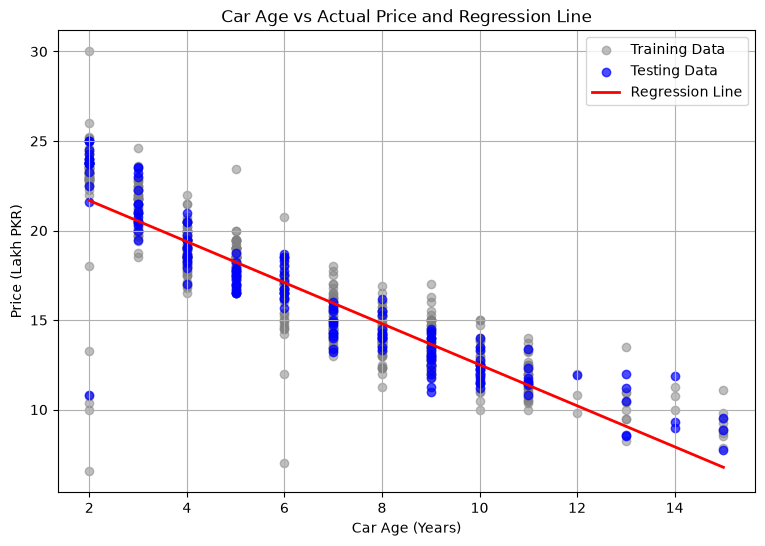

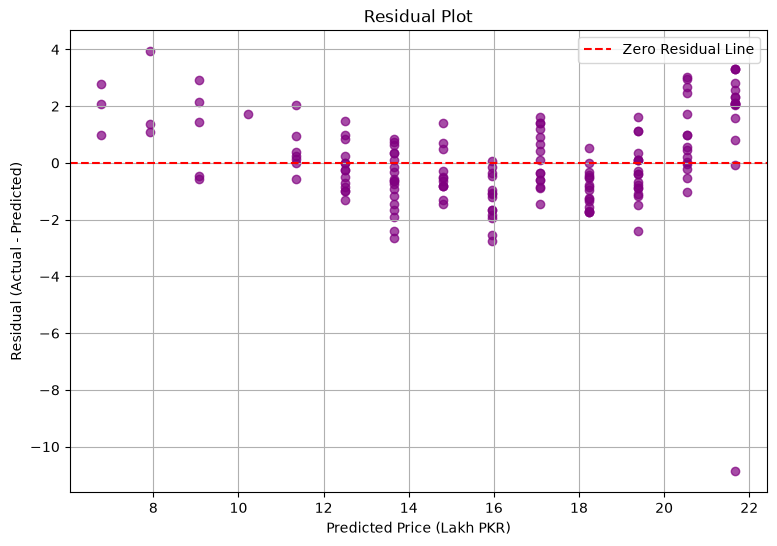

T6(c) Five test cars with the largest prediction errors:
       Year  KMs Driven Registered City  Actual_Price  Predicted_Price  Absolute_Error
18857  2018         NaN         Unknown         10.80            21.67           10.87
20280  2006    220000.0       Islamabad         11.85             7.92            3.93
17363  2018         NaN         Unknown         25.00            21.67            3.33
18980  2018         NaN         Unknown         25.00            21.67            3.33
16557  2018       300.0         Unknown         25.00            21.67            3.33


In [7]:

# Task 6(a): Plot training data, testing data and regression line

plt.figure(figsize=(9, 6))

plt.scatter(
    X_train["Age"],
    y_train,
    color="grey",
    alpha=0.5,
    label="Training Data"
)

plt.scatter(
    X_test["Age"],
    y_test,
    color="blue",
    alpha=0.7,
    label="Testing Data"
)

age_range = np.linspace(
    X_train["Age"].min(),
    X_train["Age"].max(),
    100
)

price_line = model.predict(pd.DataFrame({"Age": age_range}))

plt.plot(
    age_range,
    price_line,
    color="red",
    linewidth=2,
    label="Regression Line"
)

plt.title("Car Age vs Actual Price and Regression Line")
plt.xlabel("Car Age (Years)")
plt.ylabel("Price (Lakh PKR)")
plt.legend()
plt.grid(True)

plt.show()


# Task 6(b): Residual plot

residuals = y_test.to_numpy() - y_pred

plt.figure(figsize=(9, 6))

plt.scatter(
    y_pred,
    residuals,
    color="purple",
    alpha=0.7
)

plt.axhline(
    y=0,
    color="red",
    linestyle="--",
    label="Zero Residual Line"
)

plt.title("Residual Plot")
plt.xlabel("Predicted Price (Lakh PKR)")
plt.ylabel("Residual (Actual - Predicted)")
plt.legend()
plt.grid(True)

plt.show()


# Task 6(c): Display five test cars with the largest absolute errors

error_analysis = X_test.copy()

error_analysis["Actual_Price"] = y_test
error_analysis["Predicted_Price"] = y_pred
error_analysis["Absolute_Error"] = np.abs(residuals)

error_analysis["Year"] = gli.loc[X_test.index, "Year"]
error_analysis["KMs Driven"] = gli.loc[X_test.index, "KMs Driven"]
error_analysis["Registered City"] = gli.loc[X_test.index, "Registered City"]

largest_errors = error_analysis.sort_values(
    by="Absolute_Error",
    ascending=False
).head(5)

print("T6(c) Five test cars with the largest prediction errors:")

print(
    largest_errors[
        [
            "Year",
            "KMs Driven",
            "Registered City",
            "Actual_Price",
            "Predicted_Price",
            "Absolute_Error"
        ]
    ].round(2)
)




The residual plot shows that most residuals are scattered around the zero line. However, one noticeable outlier has a large negative residual, which means that the model predicted a much higher price than the actual price. The residuals do not show a perfectly uniform pattern, indicating that the model does not explain every price difference equally well.

The five cars with the largest absolute errors show that the model sometimes makes inaccurate predictions. The largest error belongs to a 2018 Corolla GLI listed at 10.80 lakh PKR, while the model predicted approximately 21.67 lakh PKR. This difference may be due to an unusual asking price, vehicle condition, or incomplete listing information. These results also show that car age alone is not enough to explain all differences in used-car prices.


## Task 7 · Use the model
- **(a)** Predict the price of a 2018, a 2015 and a 2010 Corolla GLI (age = 2020 − year), using a DataFrame with an `Age` column.
- **(b)** Predict the price of a 1995 Corolla GLI (age 25).

**Write (Markdown):** is the answer in (b) believable? Why not?

In [8]:

# Task 7(a): Predict prices for selected car years

years = [2018, 2015, 2010]

ages = [2020 - year for year in years]

new_cars = pd.DataFrame({"Age": ages})

predicted_prices = model.predict(new_cars)

print("T7(a) Predicted car prices:")

for year, age, price in zip(years, ages, predicted_prices):
    print(f"Year: {year}, Age: {age}, Predicted Price: {price:.2f} lakh PKR")


# Task 7(b): Predict the price of a 1995 car

old_car = pd.DataFrame({"Age": [25]})

old_car_prediction = model.predict(old_car)

print("\nT7(b) 1995 car predicted price:", round(old_car_prediction[0], 2), "lakh PKR")



T7(a) Predicted car prices:
Year: 2018, Age: 2, Predicted Price: 21.67 lakh PKR
Year: 2015, Age: 5, Predicted Price: 18.24 lakh PKR
Year: 2010, Age: 10, Predicted Price: 12.51 lakh PKR

T7(b) 1995 car predicted price: -4.68 lakh PKR



The model predicts that a 2018 Corolla GLI will cost approximately 21.67 lakh PKR, a 2015 model approximately 18.24 lakh PKR, and a 2010 model approximately 12.51 lakh PKR.

For a 1995 car, the model predicts a negative price of approximately -4.68 lakh PKR. This prediction is not realistic because a car cannot have a negative price. The model was trained on cars with ages between 2 and 15 years, whereas a 1995 car has an age of 25 years. Therefore, this is an example of extrapolation, and the prediction should not be considered reliable.


## Task 8 · Reflection (Markdown cell)
Write 3–5 sentences: the steps you followed to build the model, why the model is judged on the test set and not the training set, which number you would tell a car buyer and why, and one limitation of using age alone.


In this lab, I learned how to perform simple linear regression using a real-world used-car dataset. I loaded and filtered the data, selected Age as the feature and Price_lakh as the target, divided the data into training and testing sets, calculated the regression equation using NumPy, and verified it using Scikit-learn. The test set is important because it evaluates the model on data that was not used during training, giving us a better idea of how it performs on unseen cars.

If I were explaining the model to a car buyer, I would use MAE because it tells us the average prediction error in lakh PKR, making it easy to understand. However, the model has a limitation because it uses only car age to predict price. Other factors, such as mileage, vehicle condition, model features, and location, can also affect a car's price.
